# 7b — Learning a Table from Experience

Q-learning and SARSA, from a frozen lake to the G1’s balance · SOC4180
Robot and AI

Hong Jeong

<figure>
<a
href="https://colab.research.google.com/github/gnoejh/soc4180/blob/main/weeks/07b-tabular/lab.ipynb"><img
src="https://colab.research.google.com/assets/colab-badge.svg" /></a>
<figcaption>Open In Colab</figcaption>
</figure>

**Before you start, two things:**

1.  **Runtime → Change runtime type → CPU is enough.** Nothing in this
    notebook renders video.
2.  **File → Save a copy in Drive.** This notebook is opened from GitHub
    and is *not* saved. Without a copy, your work disappears when you
    close the tab.

A few cells **train** for up to a minute or two. That is normal.

## Today: learning from experience, with a table

Week 7 **solved** the G1’s balance: ${\color{#c0392b}{P}}$ and
${\color{#2a9d5c}{R}}$ were arrays, and value iteration found ${\pi^*}$
($J = 72.12$). But `env.step` never hands you ${\color{#c0392b}{P}}$ —
it only answers “you did ${\color{#e8743b}{a}}$ in $s$; here is $s'$ and
${\color{#2a9d5c}{r}}$”.

Today the agent learns **from those answers alone**, keeping a table of
how good each action is. Four worlds, one learning rule:

| world | what it teaches |  |
|------------------------|------------------------|------------------------|
| **FrozenLake** (4 × 4, slippery) | the rule itself, checked against value iteration’s exact answer | gymnasium |
| **CliffWalking** (4 × 12) | two versions of the rule, and why they learn different paths | gymnasium |
| **Inverted pendulum** (MuJoCo) | a continuous state, cut into bins; what the table must *see* | gymnasium + MuJoCo |
| **The G1’s balance** (week 7) | the same rule on our robot, against the exact 72.12 | numpy |

and then **why tables stop working** — which is where week 8 starts.

This is **Layer 5** — learning — at its simplest: no network, no
gradient, one table.

------------------------------------------------------------------------

## Colour code for the week

| symbol | meaning | colour |
|------------|----------------------------------------------------|---------|
| ${\color{#3b7dd8}{Q(s,a)}}$, ${\color{#3b7dd8}{V(s)}}$ | the **table**: how good action $a$ is in state $s$, and how good $s$ is — *the only thing learning changes* | <span style="color:#3b7dd8">blue</span> |
| ${\color{#e8743b}{a}}$, ${\color{#e8743b}{a'}}$ | the **action** taken now, and the one taken next | <span style="color:#e8743b">orange</span> |
| ${\color{#2a9d5c}{r}}$, ${\color{#2a9d5c}{y}}$ | the **reward** one step gives, and the **target**: what this sample says $Q$ should be | <span style="color:#2a9d5c">green</span> |
| ${\color{#c0392b}{\delta}}$, ${\color{#c0392b}{P}}$ | the **TD error** (target minus table), and the transition probabilities the learner never sees | <span style="color:#c0392b">red</span> |
| ${\color{#8e44ad}{\gamma}}$, ${\color{#8e44ad}{\alpha}}$, ${\color{#8e44ad}{\varepsilon}}$ | the three **knobs**: discount (week 7), learning rate, exploration | <span style="color:#8e44ad">purple</span> |

Plain black: $s$ the state now, $s'$ the next one.

*Every cell that computes a number shows its code; the code that only
draws a figure is in `lab.ipynb`.*

------------------------------------------------------------------------

## The slippery lake: P, printed

In [1]:
import importlib.util
try:                                       # find_spec raises when no 'google' package exists at all
    on_colab = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    on_colab = False
if on_colab:
    %pip install -q --upgrade "soc4180[env] @ git+https://github.com/gnoejh/soc4180.git"
import soc4180, inspect, time
import numpy as np, gymnasium as gym
from soc4180 import tabular

lake = gym.make("FrozenLake-v1", is_slippery=True)
P = lake.unwrapped.P                       # gymnasium keeps P for its toy worlds; MuJoCo envs do not
print("tile 0, action 'right': (probability, next tile, reward, episode over)")
for row in P[0][2]:
    print("   ", row)

tile 0, action 'right': (probability, next tile, reward, episode over)
    (0.33333333333333337, 4, 0, False)
    (0.3333333333333333, 1, 0, False)
    (0.33333333333333337, 0, 0, False)

From tile 0, asking for *right* lands right, down, or stays (against the
wall), one third each.

------------------------------------------------------------------------

## The slippery lake, drawn

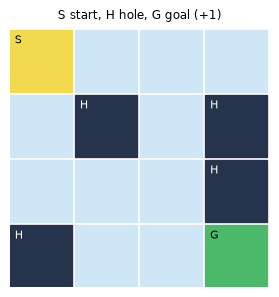

In [2]:
import matplotlib.pyplot as plt
BLUE, ORANGE, GREEN, RED, PURPLE = "#3b7dd8", "#e8743b", "#2a9d5c", "#c0392b", "#8e44ad"
LAKE = ["SFFF", "FHFH", "FFFH", "HFFG"]
CLIFF = ["." * 12, "." * 12, "." * 12, "S" + "C" * 10 + "G"]
TILE_COL = {"S": "#f2d94e", "F": "#cfe6f7", "H": "#26334d", "G": "#4cb86a", "C": "#c0392b", ".": "#e6e6e6"}
LAKE_DXY = {0: (-1, 0), 1: (0, -1), 2: (1, 0), 3: (0, 1)}        # left, down, right, up
CLIFF_DXY = {0: (0, 1), 1: (1, 0), 2: (0, -1), 3: (-1, 0)}       # up, right, down, left

def draw_grid(ax, rows, Q=None, dxy=None, values=None, path=None, title=""):
    for r, line in enumerate(rows):
        for c, ch in enumerate(line):
            s = r * len(line) + c
            col = TILE_COL[ch]
            if values is not None and ch in "FS.":
                col = plt.cm.Blues(0.15 + 0.8 * values[s] / max(values.max(), 1e-9))
            ax.add_patch(plt.Rectangle((c, -r), 0.96, 0.96, color=col))
            if values is not None and ch in "FS.":
                ax.text(c + 0.48, -r + 0.2, f"{values[s]:.2f}", ha="center", fontsize=7,
                        color="w" if values[s] > 0.5 * values.max() else "k")
            if Q is not None and ch not in "HGC" and Q[s].any():
                dx, dy = dxy[int(np.argmax(Q[s]))]
                ax.annotate("", xy=(c + 0.48 + 0.3 * dx, -r + 0.55 + 0.3 * dy),
                            xytext=(c + 0.48 - 0.3 * dx, -r + 0.55 - 0.3 * dy),
                            arrowprops=dict(arrowstyle="->", lw=1.8, color="k"))
            if ch in "SHGC":
                ax.text(c + 0.08, -r + 0.75, ch, fontsize=8, color="w" if ch in "HC" else "k")
    if path is not None:
        pts = np.array([[s % len(rows[0]) + 0.48, -(s // len(rows[0])) + 0.48] for s in path])
        ax.plot(pts[:, 0], pts[:, 1], "-", color=ORANGE, lw=3, alpha=0.8)
    ax.set_xlim(0, len(rows[0])); ax.set_ylim(-len(rows) + 1, 1); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=9)

fig, ax = plt.subplots(figsize=(3.2, 3.2)); draw_grid(ax, LAKE, title="S start, H hole, G goal (+1)")
fig.tight_layout(); plt.show()

The ice sends you where you meant only **1 time in 3**, otherwise to one
side. Reward 1 at G, 0 elsewhere; a hole ends the episode. Here
${\color{#c0392b}{P}}$ is printed — so week 7’s method applies first.

------------------------------------------------------------------------

## Value iteration on the lake: the answer to check against

In [3]:
Vstar, Qstar, sweeps = tabular.value_iteration(P, 16, 4, gamma=0.99)
pi_win = tabular.run_greedy(lake, Qstar, 2000, 10**6)[0].mean()    # 2000 tries of pi*
print(f"{sweeps} sweeps;  V*(start) = {Vstar[0]:.3f};  pi* reaches the goal {pi_win:.3f} of the time")

571 sweeps;  V*(start) = 0.542;  pi* reaches the goal 0.737 of the time

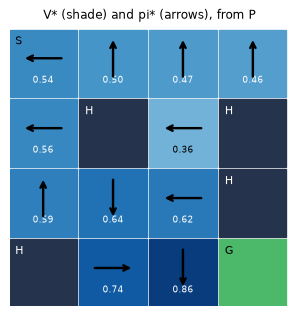

In [4]:
fig, ax = plt.subplots(figsize=(3.4, 3.4))
draw_grid(ax, LAKE, Qstar, LAKE_DXY, values=Vstar, title="V* (shade) and pi* (arrows), from P")
fig.tight_layout(); plt.show()

Even the best policy reaches G only about 3 times in 4 — the ice decides
the rest. Look at the start: π\* goes **left, into the wall**. A wall
cannot slip you into a hole; the ice then carries you down.

------------------------------------------------------------------------

## The table we want: action values

Week 7’s ${\color{#3b7dd8}{V^*(s)}}$ is the value of a *state*. Learning
needs the value of an *action*:

$$\begin{aligned}
&\text{(1)}\quad {\color{#3b7dd8}{Q^*(s,{\color{#e8743b}{a}})}} \;=\; \sum_{s'} {\color{#c0392b}{P(s'\mid s,{\color{#e8743b}{a}})}}\,\Big[{\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\,{\color{#3b7dd8}{V^*(s')}}\Big] && \text{do } {\color{#e8743b}{a}} \text{ once, then act well}\\
&\text{(2)}\quad {\color{#3b7dd8}{V^*(s')}} \;=\; \max_{{\color{#e8743b}{a'}}} {\color{#3b7dd8}{Q^*(s',{\color{#e8743b}{a'}})}} && \text{acting well = the best action}\\
&\text{(3)}\quad {\color{#3b7dd8}{Q^*(s,{\color{#e8743b}{a}})}} \;=\; \mathbb{E}_{s'\sim {\color{#c0392b}{P}}}\Big[{\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\,\max_{{\color{#e8743b}{a'}}} {\color{#3b7dd8}{Q^*(s',{\color{#e8743b}{a'}})}}\Big] && \text{(2) into (1): Bellman for } Q
\end{aligned}$$

- ${\color{#3b7dd8}{Q^*(s,a)}}$ — the return if you take
  ${\color{#e8743b}{a}}$ now and act optimally afterwards
- the policy is **read off the table**:
  $\pi^*(s) = \arg\max_a {\color{#3b7dd8}{Q^*(s,a)}}$ — no
  ${\color{#c0392b}{P}}$ needed to act

Equation (3) still contains ${\color{#c0392b}{P}}$, through the average
over $s'$. The next slide removes it.

------------------------------------------------------------------------

## Deriving Q-learning: replace the average by samples

**Step 4 — an average can be built one sample at a time.** The mean of
$y_1 \dots y_n$ satisfies

$$m_n = m_{n-1} + \tfrac{1}{n}\,(y_n - m_{n-1}) \qquad\text{(new mean = old mean + a fraction of the surprise)}$$

**Step 5 — each step of experience is one sample of the average in
(3).** The env drew $s'$ from ${\color{#c0392b}{P}}$ for us, so
${\color{#2a9d5c}{y}} = {\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\max_{a'}{\color{#3b7dd8}{Q(s',a')}}$
is one draw of the bracket. Use a fixed fraction
${\color{#8e44ad}{\alpha}}$ instead of $1/n$:

$$\boxed{\;{\color{#3b7dd8}{Q(s,{\color{#e8743b}{a}})}} \;\leftarrow\; {\color{#3b7dd8}{Q(s,{\color{#e8743b}{a}})}} + {\color{#8e44ad}{\alpha}}\,\Big[\underbrace{{\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\max_{{\color{#e8743b}{a'}}}{\color{#3b7dd8}{Q(s',{\color{#e8743b}{a'}})}}}_{\color{#2a9d5c}{\text{target } y}} - {\color{#3b7dd8}{Q(s,{\color{#e8743b}{a}})}}\Big]\;}$$

- the bracket is the **TD error** ${\color{#c0392b}{\delta}}$: what this
  one step says, minus what the table said
- ${\color{#8e44ad}{\alpha}}$ fixed (not $1/n$) keeps learning when the
  target itself changes — and it does, because the target uses the table
- if the episode **ended** at $s'$ (a hole, the goal), there is no
  future: ${\color{#2a9d5c}{y}} = {\color{#2a9d5c}{r}}$ (week 7’s
  *terminated*)

${\color{#c0392b}{P}}$ is gone. Only
$(s, {\color{#e8743b}{a}}, {\color{#2a9d5c}{r}}, s')$ from `env.step` is
used.

------------------------------------------------------------------------

## Q-learning, the code that made every number today

In [5]:
print(inspect.getsource(tabular.Learner.pick))
print(inspect.getsource(tabular.Learner.episode))

    def pick(self, s: int) -> int:
        """Epsilon-greedy: a random action with probability epsilon, else the best (ties broken at random)."""
        n = self.Q.shape[1]
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(n))
        row = self.Q[s]
        return int(self.rng.choice(np.flatnonzero(row == row.max())))

    def episode(self) -> float:
        obs, _ = self.env.reset(seed=self.seed * 100_000 + self.episodes)
        s = self.index(obs)
        a = self.pick(s)
        total, steps = 0.0, 0
        while True:
            obs, r, terminated, truncated, _ = self.env.step(self.act(a))
            s2 = self.index(obs)
            total += r
            steps += 1
            if self.algo == "sarsa":
                a2 = self.pick(s2)                                       # choose first ...
                future = self.Q[s2, a2]                                  # ... and value THAT action
            else:
                future = self.Q

`pick` is **ε-greedy**: a random action with probability
${\color{#8e44ad}{\varepsilon}}$ (explore), otherwise the table’s best
(exploit). The update is the boxed line; `terminated` is the “no future”
rule.

------------------------------------------------------------------------

## Q-learning on the lake, measured

In [6]:
L = tabular.Learner(lake, 16, 4, algo="q", alpha=0.05, gamma=0.99,
                    epsilon=1.0, eps_decay=0.9995, eps_min=0.05, seed=0)   # explore a lot, then less
snap, reach = {}, Vstar > 0                    # tiles from which the goal can be reached
print("episodes  success   max |max_a Q - V*|   same action as pi*")
for upto in (100, 500, 1000, 2000, 5000):
    L.train(upto - L.episodes)
    snap[upto] = L.Q.copy()
    ql_win = tabular.run_greedy(lake, L.Q, 2000, 10**6)[0].mean()
    gap = np.abs(L.Q.max(1) - Vstar)[reach].max()
    same = (L.Q.argmax(1) == Qstar.argmax(1))[reach].mean()
    print(f"{upto:8d}  {ql_win:7.3f}   {gap:18.3f}   {same:8.0%}")

episodes  success   max |max_a Q - V*|   same action as pi*
     100    0.093                0.810        36%
     500    0.158                0.703        36%
    1000    0.270                0.588        55%
    2000    0.646                0.360        73%
    5000    0.737                0.079       100%

From samples alone, the table reaches value iteration’s answer: same
success, the same action on every tile that matters, values within 0.08.
It took **5000 episodes** to learn what ${\color{#c0392b}{P}}$ said in
571 sweeps.

------------------------------------------------------------------------

## The table filling in, drawn

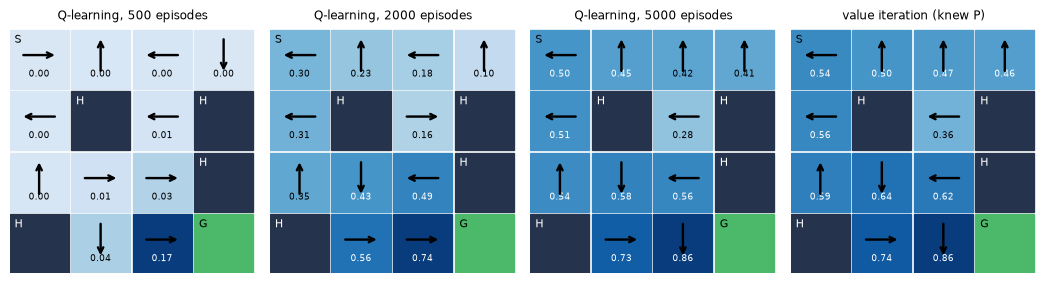

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(11, 3.1))
for ax, k in zip(axs[:3], (500, 2000, 5000)):
    draw_grid(ax, LAKE, snap[k], LAKE_DXY, values=snap[k].max(1), title=f"Q-learning, {k} episodes")
draw_grid(axs[3], LAKE, Qstar, LAKE_DXY, values=Vstar, title="value iteration (knew P)")
fig.tight_layout(); plt.show()

Values spread **backwards from the goal**: a tile is worth something
only once a tile after it is. That is
${\color{#8e44ad}{\gamma}}\max_{a'}{\color{#3b7dd8}{Q(s',a')}}$ in the
target — the table bootstraps off itself (week 7).

------------------------------------------------------------------------

## How far it looks: γ on the lake

In [8]:
print("gamma   pi* by value iteration   Q-learning, 5000 episodes (seeds 0, 1, 2)")
for g in (0.5, 0.8, 0.9, 0.95, 0.99, 1.0):
    _, Qg, _ = tabular.value_iteration(P, 16, 4, g)
    vi = tabular.run_greedy(lake, Qg, 2000, 10**6)[0].mean()
    ql = [tabular.run_greedy(lake, tabular.Learner(lake, 16, 4, alpha=0.05, gamma=g, epsilon=1.0,
                             eps_decay=0.9995, eps_min=0.05, seed=s).train(5000).Q, 2000, 10**6)[0].mean()
          for s in range(3)]
    print(f"{g:5.2f}   {vi:22.3f}   " + "  ".join(f"{x:.3f}" for x in ql))

gamma   pi* by value iteration   Q-learning, 5000 episodes (seeds 0, 1, 2)
 0.50                    0.465   0.070  0.073  0.066
 0.80                    0.442   0.389  0.249  0.506
 0.90                    0.730   0.730  0.506  0.681
 0.95                    0.730   0.607  0.640  0.734
 0.99                    0.737   0.737  0.737  0.737
 1.00                    0.737   0.737  0.737  0.737

- **Low ${\color{#8e44ad}{\gamma}}$ makes the long, safe route worth too
  little.** With ${\color{#8e44ad}{\gamma}} \le 0.8$ even the exact
  answer prefers short and risky.
- **Samples need more than the exact answer does.** At 0.9 and 0.95
  value iteration still finds the safe route, but the gap between the
  two routes’ values shrinks with ${\color{#8e44ad}{\gamma}}$ — below
  what 5000 noisy episodes can resolve.

------------------------------------------------------------------------

## A second rule: SARSA

Q-learning’s target uses the **best** next action — the one it *would*
take if it stopped exploring. SARSA uses the action it **will actually
take** (ε-greedy included):

$$\begin{aligned}
&\text{Q-learning:}\quad {\color{#2a9d5c}{y}} = {\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\,\max_{{\color{#e8743b}{a'}}} {\color{#3b7dd8}{Q(s',{\color{#e8743b}{a'}})}} && \textbf{off-policy:}\ \text{learns about the greedy policy, whatever it does}\\
&\text{SARSA:}\quad\;\; {\color{#2a9d5c}{y}} = {\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\, {\color{#3b7dd8}{Q(s',{\color{#e8743b}{a'}})}},\ \ {\color{#e8743b}{a'}} \sim \varepsilon\text{-greedy} && \textbf{on-policy:}\ \text{learns about what it really does}
\end{aligned}$$

The name is the sample it uses:
$(s, {\color{#e8743b}{a}}, {\color{#2a9d5c}{r}}, s', {\color{#e8743b}{a'}})$.
In `Learner.episode` it is two lines: choose ${\color{#e8743b}{a'}}$
first, then value *that* action.

**CliffWalking:** 4 × 12 tiles, ${\color{#2a9d5c}{r}} = -1$ per step;
stepping into the cliff (bottom edge) costs $-100$ and sends you back to
S. ${\color{#8e44ad}{\varepsilon}} = 0.1$ throughout: one move in ten is
random.

------------------------------------------------------------------------

## On-policy or off-policy: who picks ${\color{#e8743b}{a'}}$?

Two policies: the **behaviour policy** *acts* and makes the data
(ε-greedy, for both rules); the **target policy** is the one whose value
the table learns. The test is the ${\color{#e8743b}{a'}}$ inside the
target ${\color{#2a9d5c}{y}}$: **is it chosen by the same policy that
chose ${\color{#e8743b}{a}}$?**

|  | ${\color{#e8743b}{a}}$, taken now | ${\color{#e8743b}{a'}}$, in the target | same policy? | the table learns |
|---------------|---------------|---------------|---------------|---------------|
| **SARSA** | ε-greedy | ε-greedy: the action it **will** take next | **yes → on-policy** | ${\color{#3b7dd8}{Q^{\pi_\varepsilon}}}$: the value of acting ε-greedily |
| **Q-learning** | ε-greedy | greedy ($\arg\max$): perhaps **never** taken | **no → off-policy** | ${\color{#3b7dd8}{Q^*}}$: the value of acting best |

So SARSA solves a different Bellman equation from (3) — the one for
**its own** policy:

$$\text{(4)}\quad {\color{#3b7dd8}{Q^{\pi}(s,{\color{#e8743b}{a}})}} \;=\; \mathbb{E}_{s'\sim {\color{#c0392b}{P}},\ {\color{#e8743b}{a'}}\sim\pi}\Big[{\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\,{\color{#3b7dd8}{Q^{\pi}(s',{\color{#e8743b}{a'}})}}\Big]$$

In `Learner.episode`: SARSA picks `a2` *before* the update and values
`Q[s2, a2]`; Q-learning values `Q[s2].max()`. At
${\color{#8e44ad}{\varepsilon}} = 0$ the behaviour policy *is* the
greedy one, and the two targets coincide.

------------------------------------------------------------------------

## The cliff, measured

In [9]:
cliff = {}
for algo in ("sarsa", "q"):
    runs = [tabular.Learner(gym.make("CliffWalking-v1"), 48, 4, algo=algo, alpha=0.5, gamma=1.0,
                            epsilon=0.1, seed=s, max_steps=1000).train(500) for s in range(3)]
    cliff[algo] = runs
    falls = [int((np.array(L.returns[-200:]) <= -100).sum()) for L in runs]
    lens = [int(tabular.run_greedy(L.env, L.Q, 1, 0, max_steps=100)[1][0]) for L in runs]
    late = [np.mean(L.returns[-200:]) for L in runs]
    print(f"{algo:5s}  while exploring: return {' '.join(f'{x:6.1f}' for x in late)}"
          f"   episodes with a fall (of 200) {falls}   greedy path, steps {lens}")

sarsa  while exploring: return  -25.1  -27.0  -30.0   episodes with a fall (of 200) [11, 7, 14]   greedy path, steps [17, 17, 19]
q      while exploring: return  -49.5  -50.6  -51.9   episodes with a fall (of 200) [51, 49, 47]   greedy path, steps [13, 13, 13]

- **SARSA falls rarely while learning** and earns more per episode; its
  learned path keeps away from the edge (17 steps).
- **Q-learning falls in about a quarter of its episodes** — yet its
  learned path is the shortest, 13 steps, along the edge.

------------------------------------------------------------------------

## The cliff, drawn

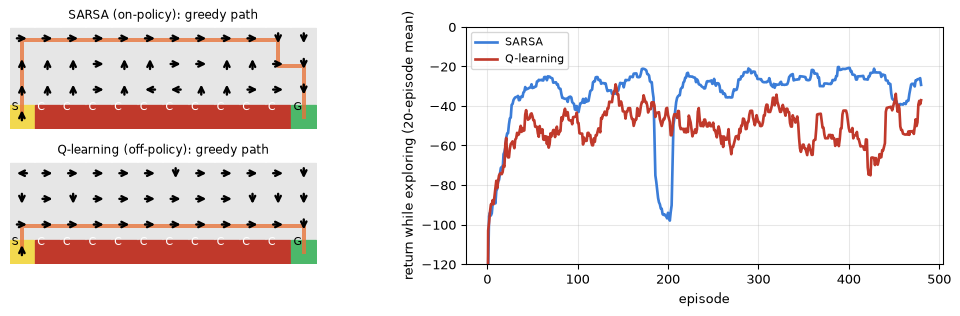

In [10]:
def greedy_path(L, limit=40):
    s, _ = L.env.reset(seed=0); path = [s]
    for _ in range(limit):
        s, r, te, tr, _ = L.env.step(int(np.argmax(L.Q[s]))); path.append(s)
        if te: break
    return path
fig = plt.figure(figsize=(11, 3.4))
for k, (algo, name) in enumerate((("sarsa", "SARSA (on-policy)"), ("q", "Q-learning (off-policy)"))):
    ax = fig.add_subplot(2, 2, 2 * k + 1)
    draw_grid(ax, CLIFF, cliff[algo][0].Q, CLIFF_DXY, path=greedy_path(cliff[algo][0]), title=name + ": greedy path")
ax = fig.add_subplot(1, 2, 2)
for algo, col, name in (("sarsa", BLUE, "SARSA"), ("q", RED, "Q-learning")):
    r = np.mean([L.returns for L in cliff[algo]], axis=0)
    ax.plot(np.convolve(r, np.ones(20) / 20, mode="valid"), color=col, lw=2, label=name)
ax.set_ylim(-120, 0); ax.set_xlabel("episode"); ax.set_ylabel("return while exploring (20-episode mean)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

Neither is wrong; they answer different questions. Q-learning values the
**edge path a perfect walker would take**; SARSA values the path **this
walker, which slips one move in ten, survives**.

------------------------------------------------------------------------

## Learning while acting at random

Back on the lake, with ${\color{#8e44ad}{\varepsilon}} = 1$ for all 5000
episodes: the agent **never uses its table**.

In [11]:
rand_wins = {}
for algo in ("q", "sarsa"):
    rand_wins[algo] = wins = [tabular.run_greedy(lake, tabular.Learner(lake, 16, 4, algo=algo, alpha=0.05, gamma=0.99,
                               epsilon=1.0, seed=s).train(5000).Q, 2000, 10**6)[0].mean() for s in range(3)]
    print(f"{algo:5s}: its greedy table reaches the goal {' / '.join(f'{w:.3f}' for w in wins)}"
          f"   (pi* {pi_win:.3f})")

q    : its greedy table reaches the goal 0.730 / 0.747 / 0.646   (pi* 0.737)
sarsa: its greedy table reaches the goal 0.308 / 0.607 / 0.128   (pi* 0.737)

- **Q-learning still learns the good table.** Its target asks “what if I
  acted *best* from $s'$?”, whatever it actually did.
- **SARSA learns the value of acting at random** — correct for that
  policy, and a poor table to follow.

**For a robot:** off-policy learning can use experience someone *else*
collected — an old controller, a human, a log. On-policy learning is
safer while it learns, because it accounts for its own mistakes.

------------------------------------------------------------------------

## Who needs ${\color{#c0392b}{P}}$? Three rules for one table

$$\begin{aligned}
&\textbf{value iteration:} && {\color{#3b7dd8}{Q(s,{\color{#e8743b}{a}})}} \leftarrow \textstyle\sum_{s'} {\color{#c0392b}{P(s'\mid s,{\color{#e8743b}{a}})}}\big[{\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\max_{{\color{#e8743b}{a'}}}{\color{#3b7dd8}{Q(s',{\color{#e8743b}{a'}})}}\big] && \text{every } (s,{\color{#e8743b}{a}}), \text{ every sweep}\\
&\textbf{Q-learning:} && {\color{#3b7dd8}{Q(s,{\color{#e8743b}{a}})}} \mathrel{+}= {\color{#8e44ad}{\alpha}}\big[{\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\max_{{\color{#e8743b}{a'}}}{\color{#3b7dd8}{Q(s',{\color{#e8743b}{a'}})}} - {\color{#3b7dd8}{Q(s,{\color{#e8743b}{a}})}}\big] && \text{one sampled } s'\\
&\textbf{SARSA:} && {\color{#3b7dd8}{Q(s,{\color{#e8743b}{a}})}} \mathrel{+}= {\color{#8e44ad}{\alpha}}\big[{\color{#2a9d5c}{r}} + {\color{#8e44ad}{\gamma}}\,{\color{#3b7dd8}{Q(s',{\color{#e8743b}{a'}})}} - {\color{#3b7dd8}{Q(s,{\color{#e8743b}{a}})}}\big] && \text{one sampled } s' \text{ and } {\color{#e8743b}{a'}}
\end{aligned}$$

|  | needs ${\color{#c0392b}{P}}$? | uses | on / off-policy | learns |
|---------------|---------------|---------------|---------------|---------------|
| **value iteration** (week 7) | **yes** — model-based | the whole table of ${\color{#c0392b}{P}}$ | neither: it never acts | ${\color{#3b7dd8}{Q^*}}$ |
| **Q-learning** | no — model-free | $(s, {\color{#e8743b}{a}}, {\color{#2a9d5c}{r}}, s')$ | **off** | ${\color{#3b7dd8}{Q^*}}$ |
| **SARSA** | no — model-free | $(s, {\color{#e8743b}{a}}, {\color{#2a9d5c}{r}}, s', {\color{#e8743b}{a'}})$ | **on** | ${\color{#3b7dd8}{Q^{\pi_\varepsilon}}}$ |

In [12]:
print(f"value iteration, knows P : {sweeps} sweeps, no episodes      -> pi* reaches G {pi_win:.3f}")
print(f"Q-learning, eps 1 -> 0.05: 5000 episodes, no P            -> greedy table    {ql_win:.3f}")
print("acting at random, eps = 1: Q-learning " + " / ".join(f"{w:.3f}" for w in rand_wins["q"])
      + ",  SARSA " + " / ".join(f"{w:.3f}" for w in rand_wins["sarsa"]))

value iteration, knows P : 571 sweeps, no episodes      -> pi* reaches G 0.737
Q-learning, eps 1 -> 0.05: 5000 episodes, no P            -> greedy table    0.737
acting at random, eps = 1: Q-learning 0.730 / 0.747 / 0.646,  SARSA 0.308 / 0.607 / 0.128

**Value iteration:** know ${\color{#c0392b}{P}}$. **Q-learning:** don’t
know ${\color{#c0392b}{P}}$; learn the *best* policy. **SARSA:** don’t
know ${\color{#c0392b}{P}}$; learn the policy *you follow*.

------------------------------------------------------------------------

## A continuous state: MuJoCo’s inverted pendulum

`InvertedPendulum-v5`: a cart on a rail keeps a pole up. It is week 4’s
LIPM upside down on wheels — the same “push under the lean” problem the
G1’s ankles solve.

In [13]:
pend = gym.make("InvertedPendulum-v5")
obs, _ = pend.reset(seed=0)
print(f"observation: {np.round(obs, 4)}   = {', '.join(tabular.PENDULUM_OBS)}")
print(f"action: a force in [{pend.action_space.low[0]}, {pend.action_space.high[0]}] N;  "
      f"decision every {pend.unwrapped.dt} s;  reward +1 per step;  ends past 0.2 rad or at 1000 steps")

observation: [ 0.0027 -0.0046 -0.0092 -0.0097]   = cart position, pole angle, cart velocity, pole angular velocity
action: a force in [-3.0, 3.0] N;  decision every 0.04 s;  reward +1 per step;  ends past 0.2 rad or at 1000 steps

A table needs a **row number**, and these are real numbers. So: **cut
each one into bins**, and give the table three actions, $-3$, $0$, $+3$
N.

In [14]:
print(inspect.getsource(tabular.Binner.__call__))

    def __call__(self, obs) -> int:
        row = 0
        for e, k, n in zip(self.edges, self.take, self.sizes):
            row = row * n + int(np.searchsorted(e, obs[k]))
        return row


Rows = product of the bin counts: pole angle (6 bins) × angular velocity
(6 bins) = 36 rows × 3 actions.

------------------------------------------------------------------------

## Training the pendulum’s table

In [15]:
edges = [[-0.12, -0.06, 0, 0.06, 0.12], [-1, -0.5, 0, 0.5, 1]]     # angle (rad), angular velocity (rad/s)
t0 = time.time()
PL = tabular.pendulum_learner(edges, take=(1, 3), seed=0)           # Q-learning, epsilon 1 -> x0.998 per episode
kb = tabular.KeepBest(PL, 3000).advance(3000)                        # check the greedy table every 250 episodes
print("greedy checks (steps balanced, of 1000):", " ".join(f"{s:.0f}" for _, s in kb.curve))
kept = tabular.run_greedy(PL.env, kb.best_Q, 10, 999_000, index=PL.index, act=PL.act)[1]
final = tabular.run_greedy(PL.env, PL.Q, 10, 999_000, index=PL.index, act=PL.act)[1]
print(f"kept table (episode {kb.when}), 10 new starts: {kept}\nfinal table, same starts:   {final}"
      f"\n{time.time() - t0:.0f} s")

greedy checks (steps balanced, of 1000): 3 21 56 101 101 99 101 101 103 140 275 1000 1000
kept table (episode 2750), 10 new starts: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
final table, same starts:   [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
37 s

36 rows, a few thousand episodes, under a minute: the pole stays up for
the full 1000 steps. Read the checks: about **100 steps for 2000
episodes, then suddenly 1000**. Other seeds do something worse:

------------------------------------------------------------------------

## Learning, and forgetting

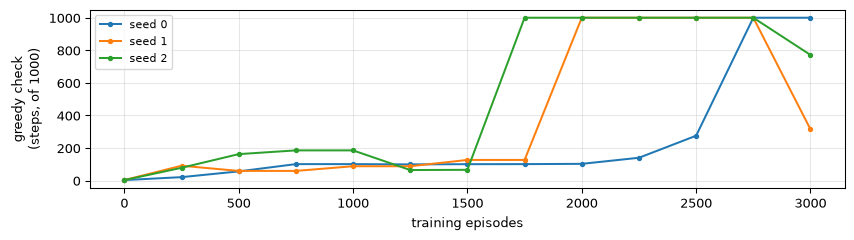

last three checks:  seed 0: 275 1000 1000   seed 1: 1000 1000 315   seed 2: 1000 1000 771

In [16]:
curves = {0: kb.curve}
for s in (1, 2):
    curves[s] = tabular.KeepBest(tabular.pendulum_learner(edges, take=(1, 3), seed=s), 3000).advance(3000).curve
fig, ax = plt.subplots(figsize=(9, 2.6))
for s, c in curves.items():
    e, v = zip(*c); ax.plot(e, v, "o-", ms=3, lw=1.5, label=f"seed {s}")
ax.set_xlabel("training episodes"); ax.set_ylabel("greedy check\n(steps, of 1000)"); ax.grid(alpha=0.3)
ax.legend(fontsize=8); fig.tight_layout(); plt.show()
print("last three checks:  " + "   ".join(f"seed {s}: {' '.join(f'{v:.0f}' for _, v in c[-3:])}" for s, c in curves.items()))

**Seeds 1 and 2 reach 1000 and then lose it.** A row lumps together
states that need different pushes, so the update for one undoes the
update for another — a **coarse table forgets**. The fix is not a new
rule but **model selection**: check the greedy table now and then, keep
the best one. Every graded pendulum result today uses the kept table.

------------------------------------------------------------------------

## What the table learned, drawn

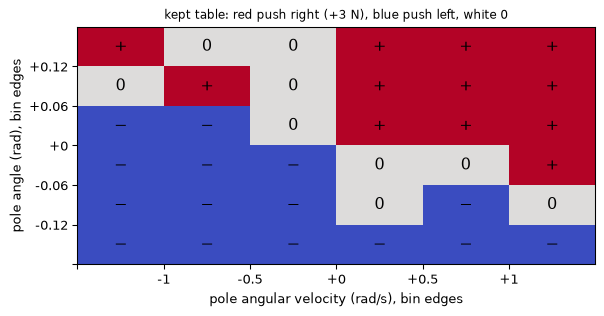

In [17]:
Qb = kb.best_Q.reshape(6, 6, 3)
act = np.where(Qb.any(-1), Qb.argmax(-1) - 1, np.nan)                 # -1 push left, 0 nothing, +1 push right
fig, ax = plt.subplots(figsize=(6.4, 3.4))
cm = plt.get_cmap("coolwarm").copy(); cm.set_bad("0.9")
ax.imshow(act, origin="lower", cmap=cm, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(np.arange(6) - 0.5, [""] + [f"{e:+g}" for e in edges[1]]); ax.set_yticks(np.arange(6) - 0.5, [""] + [f"{e:+g}" for e in edges[0]])
ax.set_xlabel("pole angular velocity (rad/s), bin edges"); ax.set_ylabel("pole angle (rad), bin edges")
for i in range(6):
    for j in range(6):
        if not np.isnan(act[i, j]): ax.text(j, i, "−0+"[int(act[i, j]) + 1], ha="center", va="center", fontsize=12)
ax.set_title("kept table: red push right (+3 N), blue push left, white 0", fontsize=9)
fig.tight_layout(); plt.show()

**Push toward the lean — and sooner if the pole is already falling that
way.** The boundary between left and right runs diagonally: a pole
leaning right but swinging back left gets no push. That is week 7’s
capture point again (where to act depends on position *and* speed),
found from +1 per step.

------------------------------------------------------------------------

## What the table must see

In [18]:
cases = {"angle only":           ([edges[0]], (1,)),
         "angle + rate":         (edges, (1, 3)),
         "angle + rate + cart":  (edges + [[-0.3, 0.3], [-0.5, 0.5]], (1, 3, 0, 2))}
for name, (e, take) in cases.items():
    Lc = tabular.pendulum_learner(e, take=take, seed=0)
    Qc = tabular.keep_best(Lc, 3000)[0]
    test = tabular.run_greedy(Lc.env, Qc, 10, 999_000, index=Lc.index, act=Lc.act)[1]
    print(f"{name:20s} {Lc.binner.n:4d} rows: kept table balances {test.mean():6.0f} steps on average (of 1000)")

angle only              6 rows: kept table balances     25 steps on average (of 1000)
angle + rate           36 rows: kept table balances   1000 steps on average (of 1000)
angle + rate + cart   324 rows: kept table balances     57 steps on average (of 1000)

- **The angle alone is not a state.** The same angle needs opposite
  pushes when the pole swings opposite ways — week 7’s *Markov*
  requirement, failing in front of you.
- **Seeing more is not free.** All four numbers: 9 times the rows, each
  visited 9 times less often — after 3000 episodes most rows are still
  mostly guesses. The **curse of dimensionality**: rows multiply with
  every number.

------------------------------------------------------------------------

## Back to week 7: the G1’s balance, from samples

Same LIPM, same ${\color{#2a9d5c}{R}}$, same pushes as week 7 — but **no
${\color{#c0392b}{P}}$**: 64 episodes at a time, 10 s each, the CoM
state $(x, v)$ cut into a `bins × bins` table, 7 centre-of-pressure
actions.

In [19]:
print(inspect.getsource(tabular.BalanceLearner.advance))

    def advance(self, rounds=1):
        m, Q, B, rng = self.mdp, self.Q, self.batch, self.rng
        for _ in range(rounds):
            x, v = np.zeros(B), rng.choice(m.PUSHES, B)
            up = np.ones(B, bool)
            for _ in range(500):
                s = self.cell(x, v)
                a = np.where(rng.random(B) < self.epsilon, rng.integers(len(m.ps), size=B), Q[s].argmax(axis=1))
                r = m.reward(x, m.ps[a])
                x, v = m.step(x, v, m.ps[a])
                fell = m.fallen(x, v)
                s2 = self.cell(x, v)
                target = r + np.where(fell, 0.0, m.gamma * Q[s2].max(axis=1))   # fallen: no future
                np.add.at(Q, (s[up], a[up]), self.alpha * (target[up] - Q[s[up], a[up]]))
                up &= ~fell
                if not up.any():
                    break
            self.epsilon = max(self.eps_min, self.epsilon * self.eps_decay)
            self.episodes += B
        return self


------------------------------------------------------------------------

## How big a table? Measured

In [20]:
mdp = tabular.BalanceMDP()
print(f"hold (p = 0): J = {mdp.J(lambda x, v: np.zeros_like(x)):.2f}     value iteration (knew P): J = {mdp.J_STAR}")
sweep = {}
for b in (5, 11, 21, 41, 81):
    t0, BL = time.time(), tabular.BalanceLearner(b, seed=0)
    for k in range(1, 1561):                          # 1560 batches of 64 = 99,840 episodes
        BL.advance(1)
        if k % 195 == 0: BL.check()                   # J of the greedy table, 8 times
    sweep[b] = [j for _, j in BL.curve]
    print(f"{b:3d} x {b:<3d} = {b * b:5d} rows: J at 8 checks {' '.join(f'{j:5.1f}' for j in sweep[b])}"
          f"   second half {np.mean(sweep[b][4:]):5.1f}   ({time.time() - t0:.0f} s)")

hold (p = 0): J = 12.66     value iteration (knew P): J = 72.12
  5 x 5   =    25 rows: J at 8 checks  25.1  45.8  23.1  20.9  43.3   9.4  12.3  11.3   second half  19.1   (37 s)
 11 x 11  =   121 rows: J at 8 checks  28.5  57.0  42.0  62.6  51.1  59.4  51.0  42.9   second half  51.1   (93 s)
 21 x 21  =   441 rows: J at 8 checks  53.9  63.0  67.5  65.6  63.8  65.4  63.5  69.4   second half  65.5   (100 s)
 41 x 41  =  1681 rows: J at 8 checks  51.4  59.0  63.4  66.6  66.2  67.5  67.8  62.8   second half  66.1   (99 s)
 81 x 81  =  6561 rows: J at 8 checks  34.9  50.8  53.4  53.5  52.6  53.8  53.0  53.9   second half  53.3   (100 s)

------------------------------------------------------------------------

## Not too coarse, not too fine, drawn

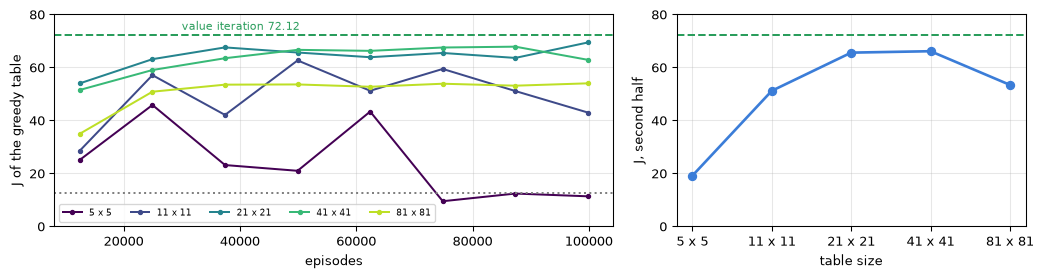

In [21]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 3.0), gridspec_kw=dict(width_ratios=[1.6, 1]))
eps_axis = 195 * 64 * np.arange(1, 9)
for b, col in zip(sweep, plt.cm.viridis(np.linspace(0, 0.9, len(sweep)))):
    ax.plot(eps_axis, sweep[b], "o-", ms=3, color=col, label=f"{b} x {b}")
ax.axhline(mdp.J_STAR, color=GREEN, ls="--"); ax.text(30000, mdp.J_STAR + 2, "value iteration 72.12", color=GREEN, fontsize=8)
ax.axhline(12.66, color="0.5", ls=":"); ax.set_ylim(0, 80); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=5)
ax.set_xlabel("episodes"); ax.set_ylabel("J of the greedy table")
bx.plot(range(len(sweep)), [np.mean(v[4:]) for v in sweep.values()], "o-", color=BLUE, lw=2)
bx.set_xticks(range(len(sweep)), [f"{b} x {b}" for b in sweep]); bx.axhline(mdp.J_STAR, color=GREEN, ls="--")
bx.set_xlabel("table size"); bx.set_ylabel("J, second half"); bx.grid(alpha=0.3); bx.set_ylim(0, 80)
fig.tight_layout(); plt.show()

- **Too coarse** (5, 11): a row spans states needing different actions —
  it never settles (the pendulum’s forgetting).
- **Too fine** (81): 6561 rows, most rarely visited — slow and stuck.
- **In between** (21, 41) gets within about 6 of 72.12 — after **100,000
  episodes**. Value iteration, *given* ${\color{#c0392b}{P}}$, took 3 s.

------------------------------------------------------------------------

## Why tables stop here

|  | rows | what it took |
|------------------------|------------------------|------------------------|
| FrozenLake | 16 | 5000 episodes to match value iteration |
| inverted pendulum, 2 numbers seen | 36 | 3000 episodes, and keeping the best table |
| G1 balance, 2 numbers, 21 bins | 441 | 100,000 episodes, still 6 below the exact answer |
| G1 walking, **71** numbers, 10 bins each | $10^{71}$ | — |

A table **remembers each row separately**: learning in one row teaches
nothing about its neighbour, so every row must be visited, many times.
With 71 numbers there are more rows than atoms in a galaxy.

**Week 8 drops the table.** The policy becomes a *function* with a few
parameters, so that what is learned in one state carries over to similar
ones — and the gradient replaces the table update.

------------------------------------------------------------------------

## What each world taught

| idea | where you saw it | the number |
|------------------------|------------------------|------------------------|
| a table can be learned from samples alone, no ${\color{#c0392b}{P}}$ | lake | 0.737 = value iteration’s 0.737: 5000 episodes against 571 sweeps with ${\color{#c0392b}{P}}$ |
| ${\color{#8e44ad}{\gamma}}$ sets how far it looks | lake | γ 0.5: 0.07; γ 0.99: 0.737 |
| off-policy learns the best table while doing anything | lake, ε = 1 | Q-learning about 0.7, SARSA about 0.35 |
| on-policy accounts for its own exploration | cliff | SARSA falls far less often; Q-learning’s path is shorter |
| the state must be Markov | pendulum | angle only: 25 steps; angle + rate: 1000 |
| rows multiply (curse of dimensionality) | pendulum, G1 | 4 numbers seen fails; 81 bins worse than 21 |
| coarse tables forget; keep the best | pendulum, G1 | 2 of 3 seeds reach 1000, then lose it |

------------------------------------------------------------------------

## Lab class: on your laptop

``` bash
uv run --extra rl weeks/07b-tabular/lab_tables.py          # the game: edit tables.py, nothing else
uv run --extra rl weeks/07b-tabular/lab_tables.py --grade --no-viewer
```

Six problems; each trains a table **live in the MuJoCo window** (arrows
= the table’s best action), plays it, grades it. `G` grades all six; the
score and a 4-letter scorer code stay on screen.

| \# | problem | you choose (in `tables.py`) | passes when |
|-----|-----------------|--------------------------|--------------------------|
| 1 | FAR-SIGHTED | lake: `gamma` | greedy table reaches the goal 70 % (3 tables) |
| 2 | WATCHER | lake, ε = 1: `"q"` or `"sarsa"` | greedy table reaches the goal 60 % |
| 3 | SAFE | cliff: `"q"` or `"sarsa"` | falls in fewer than 25 of the last 200 episodes |
| 4 | SHORT | cliff: `"q"` or `"sarsa"` | greedy path is 13 steps |
| 5 | PENDULUM | which numbers the table sees, and their cut points | kept table balances 1000 steps from 10 starts |
| 6 | G1 BALANCE | `bins` | J ≥ 60 over the second half of 100,000 episodes |

------------------------------------------------------------------------

## Lab class: `qlearn.py`, every world measured

``` bash
uv run --extra rl weeks/07b-tabular/qlearn.py --task frozen             # value iteration vs Q-learning
uv run --extra rl weeks/07b-tabular/qlearn.py --task cliff              # SARSA vs Q-learning, maps printed
uv run --extra rl weeks/07b-tabular/qlearn.py --task pendulum --see angle rate
uv run --extra rl weeks/07b-tabular/qlearn.py --task balance --bins 11 21 41
```

Each prints its measurements, then replays in the viewer: the greedy
agent walking the grid, the kept pendulum table live (**ctrl +
right-drag the pole to push it**), the G1’s CoM catching three pushes.

| Section | Does | Calls |
|------------------------|------------------------|------------------------|
| 1 | lake: P printed, value iteration, Q-learning at 100 … 5000 episodes | `value_iteration`, `Learner`, `run_greedy` |
| 2 | cliff: both rules, falls while learning, greedy maps | `Learner(algo=...)` |
| 3 | pendulum: bins, keep-best checks, the learned table drawn | `pendulum_learner`, `KeepBest` |
| 4 | G1 balance: one row per table size | `BalanceLearner`, `BalanceMDP.J` |
| 5 | replay | `launch_viewer(passive=True)`, `mocap_pos`, `user_scn` |

------------------------------------------------------------------------

## Exercises

1.  **Learning rate.** On the lake, try
    ${\color{#8e44ad}{\alpha}} = 0.5$ and $0.005$ (`qlearn.py --alpha`).
    Which learns faster at first, which ends closer to $V^*$? Use step 4
    of the derivation to explain.
2.  **Exploration on the cliff.** Run SARSA with
    ${\color{#8e44ad}{\varepsilon}} = 0.2$ and $0.02$. Where does its
    path go, and why?
3.  **No zero.** Give the pendulum only $\pm 3$ N (edit `forces` in
    `pendulum_learner`). Predict, then measure.
4.  **Fewer cuts.** Cut the pole angle at 0 only (2 bins) and keep 6
    velocity bins. Does it still balance? What does that say about what
    the table actually needs from the angle?
5.  **Bootstrapping.** On paper: why does the lake’s value spread from G
    backwards, one tile per update at best?
6.  **The exact answer’s price.** Value iteration on the G1 balance
    takes 3 s; Q-learning 100,000 episodes. Name what value iteration
    was given that the learner was not, and say whether a real robot
    could give it.

------------------------------------------------------------------------

## Next week

**08 — policy gradients and PPO.** A table cannot hold the walking G1:
71 numbers, $10^{71}$ rows.

Next week the policy becomes a function with parameters, and the reward
reaches them through a gradient — starting, again, on a pendulum, then
week 7’s balance against its exact 72.12, then the G1 itself.